Experiencia de clientes:

¿Cuantas horas de campaña, retencion y soporte deberian programarse next week?


Buscamos maximizar el aporte esperado cumpliendo recursos, siempre cumpliendo minimos de serviciois y cotas operativas.

Aporte Campañas:
=> Contactar 9 | Consume 4k, 2hrs
=> Retencion 13 | Consume 6k, 3hrs
=> Soporte 8 | Consume 3k, 4 hrs

Presupuesto: 120k
Horas: 80 hrs

Exige:
5 < R < 15
4 < S < 12
C < 20 

Es viable?

Funcion objetivo: Aporte MAX => aC + bR + cC

feasible => 260 max R
            160 max S
            

<hr>

Improvements:

Anotar terminos y definiciones de cada métrica y unidades

In [ ]:
from ortools.linear_solver import pywraplp

solver = pywraplp.Solver.CreateSolver("GLOP")
assert solver is not None, "No se pudo crear el solver GLOP"

# Unidades de campaña (C), retención (R) y soporte (S) para la próxima semana.
# Cotas operativas y mínimos de servicio.
C = solver.NumVar(0, 20, "C")
R = solver.NumVar(5, 15, "R")
S = solver.NumVar(4, 12, "S")

# Presupuesto (miles) y horas disponibles.
solver.Add(4 * C + 6 * R + 3 * S <= 120, "presupuesto")
solver.Add(2 * C + 3 * R + 4 * S <= 80, "horas")

# Maximizar aporte esperado.
solver.Maximize(9 * C + 13 * R + 8 * S)

status = solver.Solve()
es_optimo = status == pywraplp.Solver.OPTIMAL
print("Viable:", es_optimo)

if es_optimo:
    print("C =", C.solution_value())
    print("R =", R.solution_value())
    print("S =", S.solution_value())
    print("Aporte óptimo =", solver.Objective().Value())
    print("Presupuesto usado =", 4 * C.solution_value() + 6 * R.solution_value() + 3 * S.solution_value())
    print("Horas usadas =", 2 * C.solution_value() + 3 * R.solution_value() + 4 * S.solution_value())

Viable: True
C = 16.5
R = 5.0
S = 8.0
Aporte óptimo = 277.5
Presupuesto usado = 120.0
Horas usadas = 80.0


<>:69: SyntaxWarning: invalid escape sequence '\,'
<>:69: SyntaxWarning: invalid escape sequence '\,'
/tmp/ipykernel_46301/1416148373.py:69: SyntaxWarning: invalid escape sequence '\,'
  ax.plot(optimo[0], optimo[2], "ko", ms=8, label="óptimo $(16.5,\,5,\,8)$")


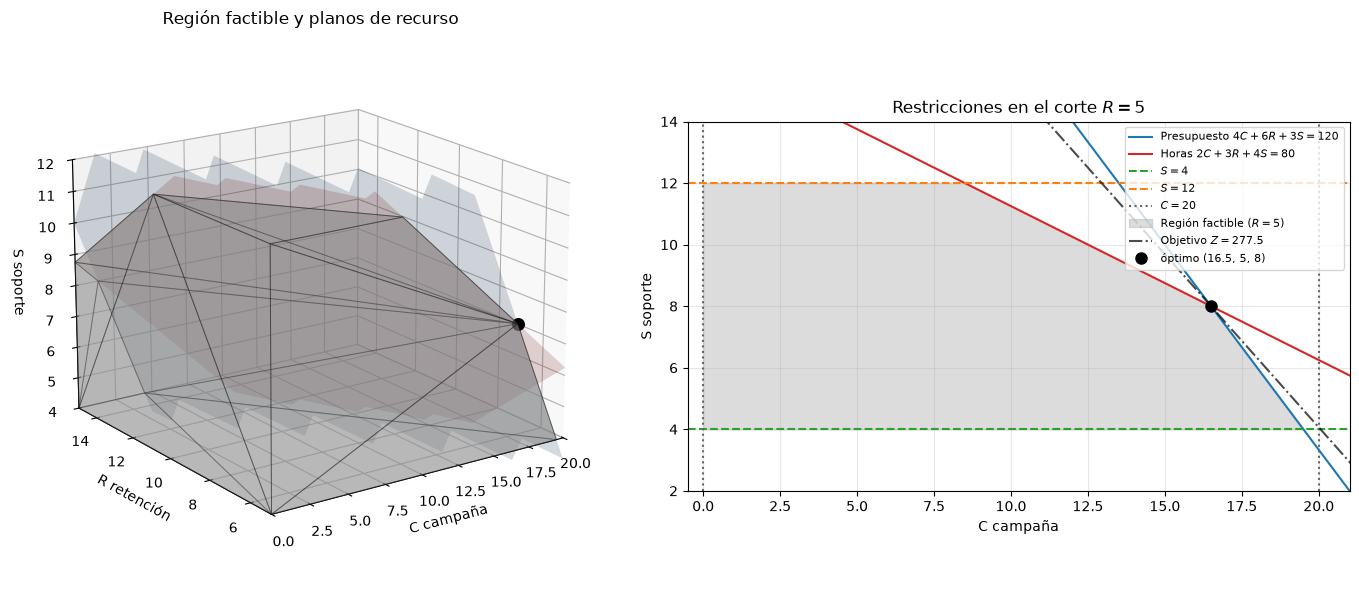

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from scipy.spatial import ConvexHull

# Vértices de la región factible (intersección de 3 restricciones activas).
vertices = np.array([
    [0.0, 5.0, 4.0],
    [0.0, 5.0, 12.0],
    [0.0, 32 / 3, 12.0],
    [0.0, 15.0, 4.0],
    [0.0, 15.0, 8.75],
    [1.5, 15.0, 8.0],
    [4.5, 15.0, 4.0],
    [8.5, 5.0, 12.0],
    [16.5, 5.0, 8.0],  # óptimo
    [19.5, 5.0, 4.0],
])
optimo = np.array([16.5, 5.0, 8.0])

fig = plt.figure(figsize=(14, 6))

# --- 3D: poliedro factible y planos de recurso ---
ax3d = fig.add_subplot(1, 2, 1, projection="3d")

Cc, Rr = np.meshgrid(np.linspace(0, 20, 25), np.linspace(5, 15, 25))
S_pres = (120 - 4 * Cc - 6 * Rr) / 3
S_horas = (80 - 2 * Cc - 3 * Rr) / 4
S_pres = np.where((S_pres >= 3) & (S_pres <= 13), S_pres, np.nan)
S_horas = np.where((S_horas >= 3) & (S_horas <= 13), S_horas, np.nan)
ax3d.plot_surface(Cc, Rr, S_pres, color="tab:blue", alpha=0.18, linewidth=0)
ax3d.plot_surface(Cc, Rr, S_horas, color="tab:red", alpha=0.18, linewidth=0)

hull = ConvexHull(vertices)
faces = [vertices[simplex] for simplex in hull.simplices]
ax3d.add_collection3d(
    Poly3DCollection(faces, alpha=0.35, facecolor="0.55", edgecolor="k", linewidths=0.7)
)
ax3d.scatter(*optimo, c="k", s=70, zorder=10, label="óptimo")

ax3d.set_xlim(0, 20)
ax3d.set_ylim(5, 15)
ax3d.set_zlim(4, 12)
ax3d.set_xlabel("C campaña")
ax3d.set_ylabel("R retención")
ax3d.set_zlabel("S soporte")
ax3d.set_title("Región factible y planos de recurso")
ax3d.view_init(elev=18, azim=-125)

# --- 2D: corte R = 5 (mínimo de retención, cara del óptimo) ---
ax = fig.add_subplot(1, 2, 2)
C = np.linspace(0, 22, 500)
S_presupuesto = (90 - 4 * C) / 3          # 4C + 6*5 + 3S = 120
S_horas_2d = (65 - 2 * C) / 4             # 2C + 3*5 + 4S = 80
S_techo = np.minimum.reduce([np.full_like(C, 12), S_presupuesto, S_horas_2d])
S_piso = np.full_like(C, 4)
factible = S_techo >= S_piso

ax.plot(C, S_presupuesto, color="tab:blue", label=r"Presupuesto $4C+6R+3S=120$")
ax.plot(C, S_horas_2d, color="tab:red", label=r"Horas $2C+3R+4S=80$")
ax.axhline(4, color="tab:green", ls="--", label=r"$S=4$")
ax.axhline(12, color="tab:orange", ls="--", label=r"$S=12$")
ax.axvline(0, color="0.4", ls=":")
ax.axvline(20, color="0.4", ls=":", label=r"$C=20$")
ax.fill_between(C, S_piso, S_techo, where=factible, color="0.7", alpha=0.45, label="Región factible $(R=5)$")

S_obj = (277.5 - 13 * 5 - 9 * C) / 8
ax.plot(C, S_obj, color="k", ls="-.", alpha=0.7, label=r"Objetivo $Z=277.5$")
ax.plot(optimo[0], optimo[2], "ko", ms=8, label="óptimo $(16.5,\,5,\,8)$")

ax.set_xlim(-0.5, 21)
ax.set_ylim(2, 14)
ax.set_xlabel("C campaña")
ax.set_ylabel("S soporte")
ax.set_title("Restricciones en el corte $R=5$")
ax.set_aspect("equal", adjustable="box")
ax.legend(loc="upper right", fontsize=8)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()